In [1]:
import os
print(os.getcwd())

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import mlxtend as xt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score



C:\Users\uliss\OneDrive\Área de Trabalho\Projeto mineração de dados\src


In [2]:
df = pd.read_csv("../data/raw/datatran2025.csv", sep=";", encoding="latin-1", decimal=",")
print(df.shape)

(72529, 30)


In [3]:
df.info()
df.isnull().sum()
print(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 72529 entries, 0 to 72528
Data columns (total 30 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      72529 non-null  int64  
 1   data_inversa            72529 non-null  str    
 2   dia_semana              72529 non-null  str    
 3   horario                 72529 non-null  str    
 4   uf                      72529 non-null  str    
 5   br                      72529 non-null  int64  
 6   km                      72529 non-null  float64
 7   municipio               72529 non-null  str    
 8   causa_acidente          72529 non-null  str    
 9   tipo_acidente           72529 non-null  str    
 10  classificacao_acidente  72528 non-null  str    
 11  fase_dia                72529 non-null  str    
 12  sentido_via             72529 non-null  str    
 13  condicao_metereologica  72529 non-null  str    
 14  tipo_pista              72529 non-null  str    
 

In [4]:
print(df["classificacao_acidente"].value_counts())
print(df["causa_acidente"].value_counts())
print(df["fase_dia"].value_counts())

classificacao_acidente
Com Vítimas Feridas    56181
Sem Vítimas            11138
Com Vítimas Fatais      5209
Name: count, dtype: int64
causa_acidente
Ausência de reação do condutor                               11469
Reação tardia ou ineficiente do condutor                     10799
Acessar a via sem observar a presença dos outros veículos     7097
Condutor deixou de manter distância do veículo da frente      4413
Velocidade Incompatível                                       4088
                                                             ...  
Faróis desregulados                                              9
Semáforo com defeito                                             8
Redutor de velocidade em desacordo                               8
Sistema de drenagem ineficiente                                  2
Sinalização encoberta                                            2
Name: count, Length: 69, dtype: int64
fase_dia
Pleno dia      40375
Plena Noite    24781
Anoitecer       3926
Am

In [5]:
df = df.dropna(subset=["classificacao_acidente"])
print(df.shape)
print(df["id"].duplicated().sum())

(72528, 30)
0


In [6]:
df["mes"] = pd.to_datetime(df["data_inversa"], format="%Y-%m-%d").dt.month
df["horas"] = pd.to_datetime(df["horario"], format="%H:%M:%S").dt.hour
df[["horario", "horas", "data_inversa", "mes"]].head()

,horario,horas,data_inversa,mes
0,06:20:00,6,2025-01-01,1
2,08:45:00,8,2025-01-01,1
3,11:00:00,11,2025-01-01,1
4,09:30:00,9,2025-01-01,1
5,10:40:00,10,2025-01-01,1


In [7]:
list_cluster = ["pessoas","veiculos","feridos","mortos"]
list_assoc = ["causa_acidente", "classificacao_acidente", "fase_dia", "condicao_metereologica","tipo_acidente"]
scaler = StandardScaler()
x = scaler.fit_transform(df[list_cluster])
print(x.shape)

(72528, 4)


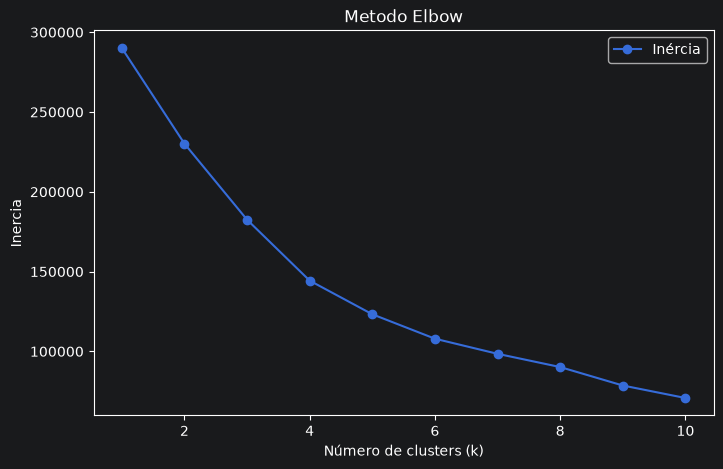

In [8]:
empty_list = []

K = range(1,11)
for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(x)
    empty_list.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K, empty_list, "o-", label="Inércia")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.title("Metodo Elbow")
plt.legend()
plt.show()

k=2: silhueta=0.632
k=3: silhueta=0.549
k=4: silhueta=0.485
k=5: silhueta=0.495
k=6: silhueta=0.437
k=7: silhueta=0.445
k=8: silhueta=0.453
Melhor k pela silhueta: 2


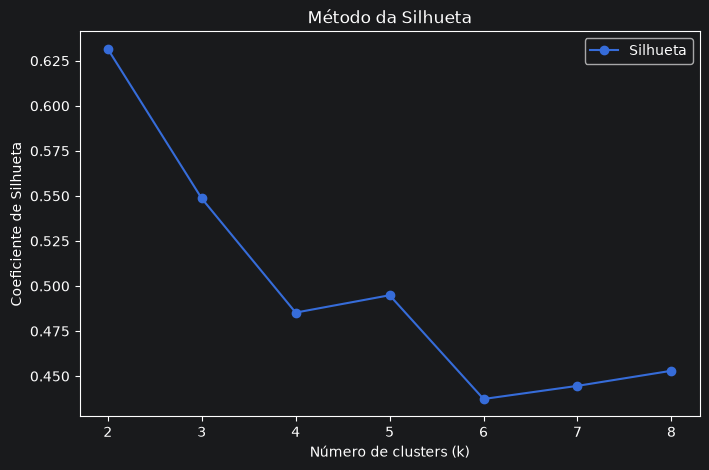

In [9]:
K_sil = range(2, 9)
silhuetas = []

for k in K_sil:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    rotulos = kmeans.fit_predict(x)
    nota = silhouette_score(x, rotulos, sample_size=10000, random_state=42)
    silhuetas.append(nota)
    print(f"k={k}: silhueta={nota:.3f}")

melhor_k = list(K_sil)[silhuetas.index(max(silhuetas))]
print("Melhor k pela silhueta:", melhor_k)

plt.figure(figsize=(8, 5))
plt.plot(K_sil, silhuetas, "o-", label="Silhueta")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Coeficiente de Silhueta")
plt.title("Método da Silhueta")
plt.legend()
plt.show()

## Escolha do k

O maior Silhouette é em k=2 (0,632), mas esse agrupamento só separa "tem morte" de "não tem morte", o que é óbvio porque `mortos` é um dos atributos. Escolhemos **k = 4**: coincide com a dobra do cotovelo, tem Silhouette ainda aceitável (≈0,485) e gera grupos mais interpretáveis.

## K-Means final (k = 4) e perfil dos grupos

In [10]:
from pathlib import Path

SAIDA = Path("../resultados")
SAIDA.mkdir(exist_ok=True)

K_FINAL = 4
modelo = KMeans(n_clusters=K_FINAL, random_state=42, n_init=10)
df["grupo"] = modelo.fit_predict(x)

perfil = df.groupby("grupo")[list_cluster].mean().round(2)
perfil["n_acidentes"] = df.groupby("grupo").size()
perfil["%_do_total"] = (perfil["n_acidentes"] / len(df) * 100).round(1)
perfil["%_fatais"] = (
    df.groupby("grupo")["classificacao_acidente"]
    .apply(lambda s: (s == "Com Vítimas Fatais").mean() * 100)
    .round(1)
)
perfil.to_csv(SAIDA / "perfil_grupos.csv", encoding="utf-8-sig")
perfil

,pessoas,veiculos,feridos,mortos,n_acidentes,%_do_total,%_fatais
grupo,,,,,,,
0,1.95,1.60,0.99,0.00,52635,72.6,0.0
1,3.10,2.43,0.58,1.15,5078,7.0,100.0
2,38.67,2.54,11.17,0.66,131,0.2,26.0
3,4.40,3.26,1.83,0.01,14684,20.2,0.7


In [11]:
cruz = pd.crosstab(
    df["grupo"], df["classificacao_acidente"], normalize="index"
).mul(100).round(1)
cruz.to_csv(SAIDA / "gravidade_por_grupo.csv", encoding="utf-8-sig")
cruz

classificacao_acidente,Com Vítimas Fatais,Com Vítimas Feridas,Sem Vítimas
grupo,,,
0,0.0,81.0,19.0
1,100.0,0.0,0.0
2,26.0,62.6,11.5
3,0.7,91.8,7.6


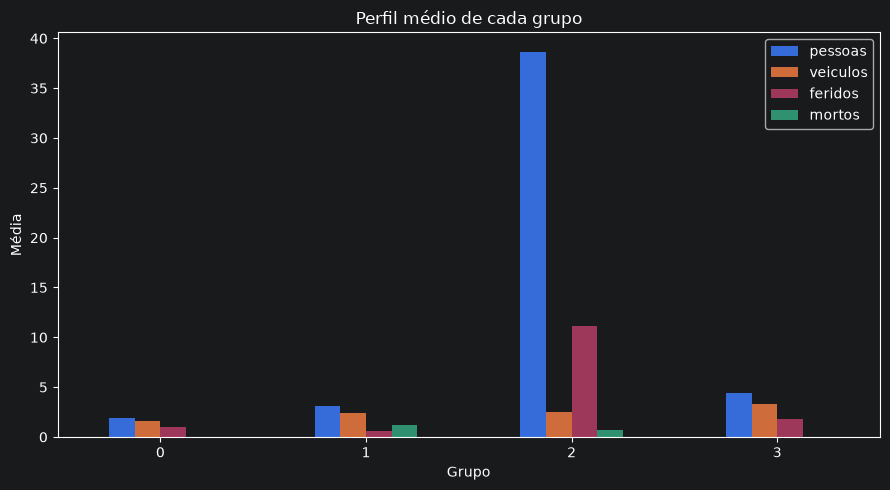

In [12]:
ax = perfil[list_cluster].plot(kind="bar", figsize=(9, 5))
ax.set_xlabel("Grupo")
ax.set_ylabel("Média")
ax.set_title("Perfil médio de cada grupo")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(SAIDA / "03_perfil_grupos.png", dpi=150)
plt.show()

**Interpretação dos grupos:**

| Grupo | Perfil |
|---|---|
| 0 | Acidentes leves/comuns: poucas pessoas e veículos, nenhuma morte (≈73%) |
| 1 | Acidentes fatais: cerca de 1 morte por acidente, 100% fatais (≈7%) |
| 2 | Muitas pessoas envolvidas (média de ~39), provavelmente ônibus; grupo raro (0,2%) |
| 3 | Acidentes maiores, com vários veículos e feridos, quase sem mortes (≈20%) |

**Limitações:** `pessoas` já inclui `mortos` e `feridos` (colunas correlacionadas); `mortos` faz o K-Means separar a gravidade de forma quase óbvia; o Silhouette foi calculado em amostra de 10.000 registros.

## Regras de associação (Apriori)

**Objetivo:** descobrir combinações de fatores (causa, tipo, fase do dia, clima) associadas à gravidade do acidente.

**Pré-processamento:** cada acidente vira uma "cesta" de itens do tipo `coluna=valor` (one-hot com `get_dummies`).

In [13]:
from mlxtend.frequent_patterns import apriori, association_rules

itens = pd.get_dummies(df[list_assoc].astype(str), prefix_sep="=").astype(bool)
print("Matriz de itens:", itens.shape)

Matriz de itens: (72528, 102)


In [14]:
freq = apriori(itens, min_support=0.01, use_colnames=True, max_len=4)
print("Itemsets frequentes:", len(freq))

try:
    regras = association_rules(
        freq, metric="confidence", min_threshold=0.3, num_itemsets=len(itens)
    )
except TypeError:
    regras = association_rules(freq, metric="confidence", min_threshold=0.3)

regras = regras[regras["lift"] > 1].copy()


def texto(conj):
    return " + ".join(sorted(conj))


regras["antecedente"] = regras["antecedents"].apply(texto)
regras["consequente"] = regras["consequents"].apply(texto)
cols_saida = ["antecedente", "consequente", "support", "confidence", "lift"]

todas = regras.sort_values("lift", ascending=False)[cols_saida]
todas.to_csv(SAIDA / "regras_todas.csv", index=False, encoding="utf-8-sig")
print("Total de regras (suporte>=1%, confiança>=30%, lift>1):", len(todas))
todas.head(10).round(3)

Itemsets frequentes: 493
Total de regras (suporte>=1%, confiança>=30%, lift>1): 680


,antecedente,consequente,support,confidence,lift
190,causa_acidente=Animais na Pista + fase_dia=Ple...,tipo_acidente=Atropelamento de Animal,0.011,0.881,56.409
191,tipo_acidente=Atropelamento de Animal,causa_acidente=Animais na Pista + fase_dia=Ple...,0.011,0.674,56.409
196,tipo_acidente=Atropelamento de Animal,causa_acidente=Animais na Pista + condicao_met...,0.011,0.673,52.576
194,causa_acidente=Animais na Pista + condicao_met...,tipo_acidente=Atropelamento de Animal,0.011,0.821,52.576
192,causa_acidente=Animais na Pista,fase_dia=Plena Noite + tipo_acidente=Atropelam...,0.011,0.585,52.099
188,fase_dia=Plena Noite + tipo_acidente=Atropelam...,causa_acidente=Animais na Pista,0.011,0.937,52.099
8,tipo_acidente=Atropelamento de Animal,causa_acidente=Animais na Pista,0.015,0.934,51.898
9,causa_acidente=Animais na Pista,tipo_acidente=Atropelamento de Animal,0.015,0.811,51.898
187,causa_acidente=Animais na Pista,classificacao_acidente=Com Vítimas Feridas + t...,0.011,0.635,51.652
184,classificacao_acidente=Com Vítimas Feridas + t...,causa_acidente=Animais na Pista,0.011,0.929,51.652


### Regras que levam a acidente fatal

Acidentes fatais são só ~7% da base, então para esse alvo usamos suporte mínimo menor (0,3%) e confiança mínima de 15%, mantendo lift > 1,5.

In [15]:
ALVO_FATAL = "classificacao_acidente=Com Vítimas Fatais"
freq_f = apriori(itens, min_support=0.003, use_colnames=True, max_len=4)
try:
    reg_f = association_rules(
        freq_f, metric="confidence", min_threshold=0.15, num_itemsets=len(itens)
    )
except TypeError:
    reg_f = association_rules(freq_f, metric="confidence", min_threshold=0.15)
reg_f["antecedente"] = reg_f["antecedents"].apply(texto)
reg_f["consequente"] = reg_f["consequents"].apply(texto)
fatal = reg_f[(reg_f["consequente"] == ALVO_FATAL) & (reg_f["lift"] > 1.5)].sort_values(
    "lift", ascending=False
)[cols_saida]
fatal.to_csv(SAIDA / "regras_fatais.csv", index=False, encoding="utf-8-sig")
print("Regras -> Fatal:", len(fatal))
fatal.head(15).round(3)

Regras -> Fatal: 22


,antecedente,consequente,support,confidence,lift
990,causa_acidente=Pedestre andava na pista + tipo...,classificacao_acidente=Com Vítimas Fatais,0.003,0.427,5.940
125,causa_acidente=Pedestre andava na pista,classificacao_acidente=Com Vítimas Fatais,0.003,0.413,5.744
3086,causa_acidente=Transitar na contramão + fase_d...,classificacao_acidente=Com Vítimas Fatais,0.004,0.392,5.459
3101,causa_acidente=Transitar na contramão + condic...,classificacao_acidente=Com Vítimas Fatais,0.006,0.391,5.447
1210,causa_acidente=Transitar na contramão + tipo_a...,classificacao_acidente=Com Vítimas Fatais,0.009,0.385,5.360
1373,fase_dia=Plena Noite + tipo_acidente=Atropelam...,classificacao_acidente=Com Vítimas Fatais,0.009,0.372,5.183
3292,condicao_metereologica=Céu Claro + fase_dia=Pl...,classificacao_acidente=Com Vítimas Fatais,0.006,0.371,5.166
3094,causa_acidente=Transitar na contramão + fase_d...,classificacao_acidente=Com Vítimas Fatais,0.003,0.370,5.152
3079,causa_acidente=Transitar na contramão + condic...,classificacao_acidente=Com Vítimas Fatais,0.003,0.326,4.537
1202,causa_acidente=Transitar na contramão + fase_d...,classificacao_acidente=Com Vítimas Fatais,0.005,0.316,4.398


**Leitura:** a taxa-base de acidente fatal é ~7,2%. Com **pedestre andando na pista**, **contramão com colisão frontal** ou **colisão frontal em céu claro**, a confiança sobe para 30–43% (lift entre 4 e 6).

### Regras de acidente fatal em formato legível

Mesmas regras, escritas como "SE ... ENTÃO ...", com suporte e confiança em % e lift arredondado (só regras com 1 item no ENTÃO).

In [16]:
NOMES = {"causa_acidente": "Causa", "tipo_acidente": "Tipo", "fase_dia": "Fase do dia",
         "condicao_metereologica": "Clima", "classificacao_acidente": "Gravidade"}


def item(s):
    col, val = s.split("=", 1)
    return f"{NOMES.get(col, col)}: {val}"


def lado(txt):
    return " E ".join(item(i) for i in txt.split(" + "))


def legivel(regras):
    out = regras[~regras["consequente"].str.contains(r" \+ ")].copy()
    out["Regra"] = "SE " + out["antecedente"].apply(lado) + "  →  ENTÃO " + out["consequente"].apply(lado)
    out["Suporte (%)"] = (out["support"] * 100).round(2)
    out["Confiança (%)"] = (out["confidence"] * 100).round(1)
    out["Lift"] = out["lift"].round(2)
    return out.sort_values("Lift", ascending=False)[["Regra", "Suporte (%)", "Confiança (%)", "Lift"]].reset_index(drop=True)


pd.set_option("display.max_colwidth", None)
legivel(fatal).head(10)

,Regra,Suporte (%),Confiança (%),Lift
0,SE Causa: Pedestre andava na pista E Tipo: Atropelamento de Pedestre → ENTÃO Gravidade: Com Vítimas Fatais,0.34,42.7,5.94
1,SE Causa: Pedestre andava na pista → ENTÃO Gravidade: Com Vítimas Fatais,0.34,41.3,5.74
2,SE Causa: Transitar na contramão E Fase do dia: Plena Noite E Tipo: Colisão frontal → ENTÃO Gravidade: Com Vítimas Fatais,0.44,39.2,5.46
3,SE Causa: Transitar na contramão E Clima: Céu Claro E Tipo: Colisão frontal → ENTÃO Gravidade: Com Vítimas Fatais,0.59,39.1,5.45
4,SE Causa: Transitar na contramão E Tipo: Colisão frontal → ENTÃO Gravidade: Com Vítimas Fatais,0.86,38.5,5.36
5,SE Fase do dia: Plena Noite E Tipo: Atropelamento de Pedestre → ENTÃO Gravidade: Com Vítimas Fatais,0.87,37.2,5.18
6,SE Clima: Céu Claro E Fase do dia: Plena Noite E Tipo: Atropelamento de Pedestre → ENTÃO Gravidade: Com Vítimas Fatais,0.56,37.1,5.17
7,SE Causa: Transitar na contramão E Fase do dia: Pleno dia E Tipo: Colisão frontal → ENTÃO Gravidade: Com Vítimas Fatais,0.32,37.0,5.15
8,SE Causa: Transitar na contramão E Clima: Céu Claro E Fase do dia: Plena Noite → ENTÃO Gravidade: Com Vítimas Fatais,0.34,32.6,4.54
9,SE Causa: Transitar na contramão E Fase do dia: Plena Noite → ENTÃO Gravidade: Com Vítimas Fatais,0.50,31.6,4.40


In [17]:
for nome, alvo in [
    ("sem_vitimas", "classificacao_acidente=Sem Vítimas"),
    ("feridas", "classificacao_acidente=Com Vítimas Feridas"),
]:
    sub = regras[regras["consequente"] == alvo].sort_values("lift", ascending=False)[cols_saida]
    sub.to_csv(SAIDA / f"regras_{nome}.csv", index=False, encoding="utf-8-sig")
    print(f"Regras -> {nome}: {len(sub)}")
    display(sub.head(5).round(3))

Regras -> sem_vitimas: 12


,antecedente,consequente,support,confidence,lift
278,causa_acidente=Demais falhas mecânicas ou elétricas + tipo_acidente=Incêndio,classificacao_acidente=Sem Vítimas,0.021,0.975,6.349
736,causa_acidente=Demais falhas mecânicas ou elétricas + condicao_metereologica=Céu Claro + tipo_acidente=Incêndio,classificacao_acidente=Sem Vítimas,0.015,0.973,6.338
99,tipo_acidente=Incêndio,classificacao_acidente=Sem Vítimas,0.024,0.972,6.332
726,causa_acidente=Demais falhas mecânicas ou elétricas + fase_dia=Pleno dia + tipo_acidente=Incêndio,classificacao_acidente=Sem Vítimas,0.011,0.972,6.327
559,condicao_metereologica=Céu Claro + tipo_acidente=Incêndio,classificacao_acidente=Sem Vítimas,0.016,0.971,6.325


Regras -> feridas: 125


,antecedente,consequente,support,confidence,lift
879,condicao_metereologica=Céu Claro + fase_dia=Pleno dia + tipo_acidente=Queda de ocupante de veículo,classificacao_acidente=Com Vítimas Feridas,0.018,0.971,1.253
499,fase_dia=Pleno dia + tipo_acidente=Queda de ocupante de veículo,classificacao_acidente=Com Vítimas Feridas,0.027,0.968,1.250
530,condicao_metereologica=Céu Claro + tipo_acidente=Queda de ocupante de veículo,classificacao_acidente=Com Vítimas Feridas,0.031,0.960,1.239
93,tipo_acidente=Queda de ocupante de veículo,classificacao_acidente=Com Vítimas Feridas,0.045,0.953,1.230
373,causa_acidente=Trafegar com motocicleta (ou similar) entre as faixas + fase_dia=Pleno dia,classificacao_acidente=Com Vítimas Feridas,0.012,0.940,1.214


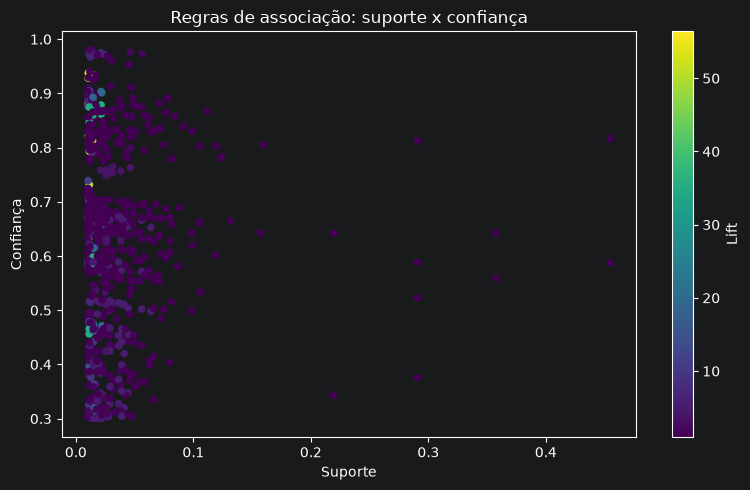

In [18]:
plt.figure(figsize=(8, 5))
sc = plt.scatter(
    regras["support"], regras["confidence"], c=regras["lift"], cmap="viridis", s=20
)
plt.colorbar(sc, label="Lift")
plt.xlabel("Suporte")
plt.ylabel("Confiança")
plt.title("Regras de associação: suporte x confiança")
plt.tight_layout()
plt.savefig(SAIDA / "04_regras_suporte_confianca.png", dpi=150)
plt.show()